# 09 · Gold standard dla etykiet LLM (Ollama) – `hate`, `hate_migrant`, `migrant`

Notebook 08 sprawdza na gold standardzie **klasyfikatory** (HerBERT, Polbert, RoBERTa-BAN-PL – tylko `hate`). Tu sprawdzamy
**LLM (Ollama)**, którego zespół używa do etykiet w analizach (`labeled/`).

**Dane:**
- gold: `data/annotation/gold/gold.csv` – 600 komentarzy (po 200 z platformy, 7 wydarzeń, 2 rundy), etykiety `hate`
  i `hate_migrants` po rozstrzygnięciu sporów,
- LLM: `data/gold_600_ollama.csv` – **te same 600 komentarzy puszczone przez Ollamę** (kolumny `migrant`, `hate`,
  `hate_migrant`) – na arkuszu `data/goldd_full.xlsx` (pusty arkusz do anotacji tych samych 600 tekstów, `item_id` G0001…).
  Komentarze łączymy z gold po tekście (wszystkie 600 tekstów jest w `gold.csv`).

**Dwa warianty LLM** (jak „sam model” / „słownik + model” dla klasyfikatorów w 08):
- **sam LLM** – odpowiedź modelu,
- **LLM + słownik** – jak w ścieżce zespołu: obelga ze słownika (`src/lexicon/slurs.py`) → `hate = 1`
  (`hate_auto`) i `hate_migrant = 1` (`hate_migrants_auto`); słownik liczony na tekście z `clean/` (tak jak w 08).

**Filtr tematyczny:** gold był losowany z komentarzy o migracji (pule `mig_hostile`, `mig_other`, `ambiguous`),
więc jest już „po filtrze” – sekcja 1 pokazuje, jaki odsetek przechodzi filtr tematyczny zespołu. Osobnej wersji
„bez filtra” nie liczymy.


In [1]:
# ── KONFIGURACJA ──────────────────────────────────────────────────────────────
GOLD = "data/annotation/gold/gold.csv"
LLM_FILE = "data/gold_600_ollama.csv"      # Ollama na wszystkich 600 komentarzach gold (item_id G0001…)
OUT_DIR = "reports/gold_llm_eval"
N_BOOT = 2000
SEED = 2026
MAIN_VARIANT = "LLM + słownik"            # wariant porównywany z klasyfikatorami (jak „słownik + model” w 08)


In [2]:
import json, re, sys, time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "events.json").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.classifier.hate_models import flag_frame, read_csv   # słownik obelg zespołu (scripts/preprocess_slurs.py)

OUT = ROOT / OUT_DIR
OUT.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_colwidth", 180)
pd.set_option("display.width", 220)

gold = read_csv(ROOT / GOLD)
for c in ("hate", "hate_migrants"):
    assert gold[c].isin(["0", "1"]).all(), f"puste etykiety {c} w gold.csv"
gold["gold_hate"] = gold["hate"].astype(int)
gold["gold_hate_migrant"] = gold["hate_migrants"].astype(int)
# item_id powtarza się między rundami gold (gold_v1 / gold_v2) -> unikalny klucz runda:item_id
gold["gold_id"] = gold["round"] + ":" + gold["item_id"]
assert gold["gold_id"].is_unique
print(f"gold: {len(gold)} komentarzy | hate=1: {gold['gold_hate'].mean():.1%} | hate_migrants=1: {gold['gold_hate_migrant'].mean():.1%}")
display(gold.groupby("platform")[["gold_hate", "gold_hate_migrant"]].agg(["sum", "mean"]).round(3))


def scores(y, p):
    y, p = np.asarray(y, int), np.asarray(p, int)
    tp, fp = int(((p == 1) & (y == 1)).sum()), int(((p == 1) & (y == 0)).sum())
    fn, tn = int(((p == 0) & (y == 1)).sum()), int(((p == 0) & (y == 0)).sum())
    prec = tp / (tp + fp) if tp + fp else 0.0
    rec = tp / (tp + fn) if tp + fn else 0.0
    spec = tn / (tn + fp) if tn + fp else 0.0
    f1 = 2 * prec * rec / (prec + rec) if prec + rec else 0.0
    npv = tn / (tn + fn) if tn + fn else 0.0
    f1n = 2 * npv * spec / (npv + spec) if npv + spec else 0.0
    den = np.sqrt(float((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn)))
    return {"n": len(y), "accuracy": (tp + tn) / len(y) if len(y) else np.nan, "precision": prec, "recall": rec,
            "f1": f1, "specificity": spec, "macro_f1": (f1 + f1n) / 2, "mcc": (tp * tn - fp * fn) / den if den else 0.0,
            "tp": tp, "fp": fp, "fn": fn, "tn": tn}


def boot_ci(y, p, metric="f1", n=N_BOOT, seed=SEED):
    rng = np.random.default_rng(seed)
    y, p = np.asarray(y, int), np.asarray(p, int)
    if len(y) < 5:
        return [np.nan, np.nan]
    vals = [scores(y[i], p[i])[metric] for i in (rng.integers(0, len(y), len(y)) for _ in range(n))]
    return np.quantile(vals, [0.025, 0.975]).round(3).tolist()


NUM = ["accuracy", "precision", "recall", "f1", "specificity", "macro_f1", "mcc"]

gold: 600 komentarzy | hate=1: 54.7% | hate_migrants=1: 29.3%


gold_hate        gold_hate_migrant       
               sum   mean               sum   mean
platform                                          
bluesky         75  0.375                18  0.090
wykop          121  0.605                73  0.365
youtube        132  0.660                85  0.425

## 1. Etykiety LLM dla 600 komentarzy gold, słownik i filtr tematyczny

In [3]:
# łączenie po tekście: arkusz Ollamy ma własne item_id (G0001…), gold – runda:item_id; 3 teksty występują w gold dwa razy
# (ten sam tekst w rundzie 1 i 2) – wtedy przypisujemy w kolejności wystąpienia (Ollama dała im identyczne etykiety)
llm_raw = read_csv(ROOT / LLM_FILE)
norm = lambda s: s.fillna("").astype(str).str.strip()
by_text = {}
for t, d in gold.groupby(norm(gold["text"]), sort=False):
    by_text[t] = list(d["gold_id"])
used, ids = {}, []
for t in norm(llm_raw["text"]):
    k = used.get(t, 0)
    ids.append(by_text[t][k] if t in by_text and k < len(by_text[t]) else None)
    used[t] = k + 1
llm_raw["gold_id"] = ids
assert llm_raw["gold_id"].notna().all() and llm_raw["gold_id"].is_unique, "nie każdy tekst z pliku Ollamy jest w gold.csv"
print(f"Ollama: {len(llm_raw)} komentarzy, połączone z gold: {llm_raw['gold_id'].notna().sum()}")

g = gold.merge(llm_raw[["gold_id", "item_id", "migrant", "hate", "hate_migrant"]]
               .rename(columns={"item_id": "llm_item_id", "migrant": "llm_migrant", "hate": "llm_hate_raw",
                                "hate_migrant": "llm_hate_migrant_raw"}), on="gold_id", how="left")
for c in ("llm_migrant", "llm_hate_raw", "llm_hate_migrant_raw"):
    g[c] = g[c].astype(float).astype(int)

# słownik obelg – na tekście z clean/ (to samo, co widzą klasyfikatory w 08)
texts = []
cache = {}
for _, r in g.iterrows():
    key = (r["platform"], r["event_folder"])
    if key not in cache:
        p = ROOT / "data" / "interim" / r["platform"] / r["event_folder"] / "clean" / "comments.csv"
        cache[key] = read_csv(p).drop_duplicates("comment_id").set_index("comment_id")["text"] if p.exists() else pd.Series(dtype=str)
    t = cache[key].get(r["comment_id"])
    texts.append(t if isinstance(t, str) and t.strip() else r["text"])
lex = flag_frame(pd.DataFrame({"comment_id": g["comment_id"], "text": texts}), "comment_id")
g["hate_auto"] = lex["hate_auto"].astype(int).values
g["hate_migrants_auto"] = lex["hate_migrants_auto"].astype(int).values

# wariant "LLM + słownik" (jak w ścieżce zespołu: obelga ze słownika -> 1/1)
g["llm_hate_migrant"] = (g["llm_hate_migrant_raw"] | g["hate_migrants_auto"]).astype(int)
g["llm_hate"] = (g["llm_hate_raw"] | g["hate_auto"] | g["llm_hate_migrant"]).astype(int)
g["llm_status"] = "Ollama (gold_600_ollama.csv)"
g["llm_covered"] = True
print(f"słownik: hate_auto = 1 w {g['hate_auto'].sum()}, hate_migrants_auto = 1 w {g['hate_migrants_auto'].sum()} komentarzach")
print(f"LLM + słownik zmienia: hate w {(g['llm_hate'] != g['llm_hate_raw']).sum()}, "
      f"hate_migrant w {(g['llm_hate_migrant'] != g['llm_hate_migrant_raw']).sum()} komentarzach")

# filtr tematyczny zespołu (scripts/topic_filter.py): obelga ze słownika ALBO słowo o migracji w komentarzu / wpisie
import importlib.util
spec = importlib.util.spec_from_file_location("topic_sample", ROOT / "scripts" / "topic_sample.py")
ts = importlib.util.module_from_spec(spec); spec.loader.exec_module(ts)
post_txt = []
for (plat, evf), d in g.groupby(["platform", "event_folder"], sort=False):
    pp = ROOT / "data" / "interim" / plat / evf / "clean" / "posts.csv"
    posts = read_csv(pp).drop_duplicates("post_id").set_index("post_id") if pp.exists() else pd.DataFrame()
    for i, r in d.iterrows():
        pt = ""
        if r["post_id"] in posts.index:
            q = posts.loc[r["post_id"]]
            pt = " ".join(str(q.get(c, "") or "") for c in ("title", "text"))
        post_txt.append((i, pt))
g["post_text"] = pd.Series(dict(post_txt))
g["w_filtrze"] = [bool(a) or ts.is_potential_migration(t, p) for a, t, p in zip(g["hate_auto"], texts, g["post_text"])]
print(f"\nfiltr tematyczny: przechodzi {g['w_filtrze'].mean():.1%} komentarzy gold "
      f"({', '.join(f'{p}: {v:.1%}' for p, v in g.groupby('platform')['w_filtrze'].mean().items())}); "
      f"poza filtrem: {(~g['w_filtrze']).sum()} (gold hate = 1: {g.loc[~g['w_filtrze'], 'gold_hate'].sum()})")
print("→ gold był losowany z komentarzy o migracji; główne metryki na wszystkich 600, dodatkowo zakres „tylko w filtrze tematycznym”.")


Ollama: 600 komentarzy, połączone z gold: 600


słownik: hate_auto = 1 w 57, hate_migrants_auto = 1 w 57 komentarzach
LLM + słownik zmienia: hate w 44, hate_migrant w 51 komentarzach



filtr tematyczny: przechodzi 89.3% komentarzy gold (bluesky: 85.5%, wykop: 99.0%, youtube: 83.5%); poza filtrem: 64 (gold hate = 1: 50)
→ gold był losowany z komentarzy o migracji; główne metryki na wszystkich 600, dodatkowo zakres „tylko w filtrze tematycznym”.


## 2. Metryki: LLM vs gold (`hate`, `hate_migrant`), dwa warianty

Klasa pozytywna = 1. CI 95% dla F1 z bootstrapu. Gold był losowany warstwowo (pule `mig_hostile`, `mig_other`, `ambiguous`
– `scripts/annotation_sample.py`), więc metryki dotyczą tej próby, a nie wszystkich komentarzy; podajemy je też per pula.


In [4]:
VARIANTS = {"sam LLM": ("llm_hate_raw", "llm_hate_migrant_raw"), "LLM + słownik": ("llm_hate", "llm_hate_migrant")}
ev = g.copy()
TASKS = {"hate": ("gold_hate", "llm_hate"), "hate_migrant": ("gold_hate_migrant", "llm_hate_migrant")}   # wariant główny (LLM + słownik)


def metric_rows(data, label_scope):
    out = []
    for variant, (ph, pm) in VARIANTS.items():
        for task, yc, pc in [("hate", "gold_hate", ph), ("hate_migrant", "gold_hate_migrant", pm)]:
            y, p = data[yc].values, data[pc].astype(int).values
            out.append({"wariant": variant, "etykieta": task, "zakres": label_scope, **scores(y, p), "f1_ci95": boot_ci(y, p),
                        "gold_pos %": round(100 * y.mean(), 1), "llm_pos %": round(100 * p.mean(), 1)})
    return out


rows = metric_rows(ev, "ogółem")
rows += metric_rows(ev[ev["w_filtrze"]], "tylko w filtrze tematycznym")
for plat, d in ev.groupby("platform"):
    rows += metric_rows(d, plat)
for pool, d in ev.groupby("pool"):
    rows += metric_rows(d, f"pula: {pool}")
llm_metrics = pd.DataFrame(rows)
llm_metrics[NUM] = llm_metrics[NUM].astype(float).round(3)
cols = ["zakres", "n", "gold_pos %", "llm_pos %", "accuracy", "precision", "recall", "f1", "f1_ci95", "mcc"]
for task in ["hate", "hate_migrant"]:
    for variant in VARIANTS:
        print(f"\n=== {task} · {variant} ===")
        display(llm_metrics[(llm_metrics["etykieta"] == task) & (llm_metrics["wariant"] == variant)][cols].set_index("zakres"))


# zgodność LLM z gold (κ Cohena, α Krippendorffa dla 2 „anotatorów”, dane binarne)
def kappa(a, b):
    a, b = np.asarray(a, int), np.asarray(b, int)
    po = (a == b).mean(); pe = a.mean() * b.mean() + (1 - a.mean()) * (1 - b.mean())
    return (po - pe) / (1 - pe) if pe < 1 else np.nan


def kripp_alpha(a, b):
    v = np.r_[np.asarray(a, int), np.asarray(b, int)]
    n, p = len(v), v.mean()
    do = (np.asarray(a, int) != np.asarray(b, int)).mean()
    de = 2 * p * (1 - p) * n / (n - 1)
    return 1 - do / de if de else np.nan


agr = []
for variant, (ph, pm) in VARIANTS.items():
    for task, yc, pc in [("hate", "gold_hate", ph), ("hate_migrant", "gold_hate_migrant", pm)]:
        agr.append({"wariant": variant, "etykieta": task, "κ Cohena (LLM vs gold)": kappa(ev[yc], ev[pc]),
                    "α Krippendorffa (LLM vs gold)": kripp_alpha(ev[yc], ev[pc]), "zgodność %": 100 * (ev[yc] == ev[pc]).mean()})
for rnd in ["gold_v1", "gold_v2"]:
    f = ROOT / "data" / "annotation" / rnd / "results" / "agreement.json"
    if f.exists():
        a = json.loads(f.read_text(encoding="utf-8"))
        for task, key in [("hate", "hate"), ("hate_migrant", "hate_migrants")]:
            agr.append({"wariant": f"Claude vs Gemini ({rnd}, przed rozstrzygnięciem)", "etykieta": task,
                        "κ Cohena (LLM vs gold)": a[key]["all"]["mean_cohen_kappa"],
                        "α Krippendorffa (LLM vs gold)": a[key]["all"]["alpha"], "zgodność %": 100 * a[key]["all"]["full_agreement"]})
print("\nZgodność (dla porównania: zgodność dwóch anotatorów gold przed rozstrzygnięciem sporów):")
display(pd.DataFrame(agr).set_index(["wariant", "etykieta"]).round(3))



=== hate · sam LLM ===


,n,gold_pos %,llm_pos %,accuracy,precision,recall,f1,f1_ci95,mcc
zakres,,,,,,,,,
ogółem,600,54.7,26.7,0.617,0.806,0.393,0.529,"[0.478, 0.581]",0.314
tylko w filtrze tematycznym,536,51.9,24.8,0.625,0.789,0.378,0.511,"[0.452, 0.567]",0.311
bluesky,200,37.5,19.5,0.670,0.615,0.320,0.421,"[0.302, 0.527]",0.244
wykop,200,60.5,28.0,0.595,0.857,0.397,0.542,"[0.448, 0.624]",0.322
youtube,200,66.0,32.5,0.585,0.877,0.432,0.579,"[0.497, 0.656]",0.318
pula: ambiguous,120,70.0,29.2,0.525,0.886,0.369,0.521,"[0.411, 0.624]",0.260
pula: mig_hostile,240,71.2,34.6,0.567,0.904,0.439,0.591,"[0.511, 0.66]",0.307
pula: mig_other,240,30.4,17.5,0.712,0.548,0.315,0.400,"[0.283, 0.505]",0.244



=== hate · LLM + słownik ===


,n,gold_pos %,llm_pos %,accuracy,precision,recall,f1,f1_ci95,mcc
zakres,,,,,,,,,
ogółem,600,54.7,34.0,0.667,0.814,0.506,0.624,"[0.579, 0.67]",0.385
tylko w filtrze tematycznym,536,51.9,33.0,0.681,0.802,0.511,0.624,"[0.573, 0.674]",0.399
bluesky,200,37.5,22.5,0.680,0.622,0.373,0.467,"[0.348, 0.569]",0.275
wykop,200,60.5,37.0,0.675,0.878,0.537,0.667,"[0.588, 0.741]",0.429
youtube,200,66.0,42.5,0.645,0.859,0.553,0.673,"[0.599, 0.739]",0.361
pula: ambiguous,120,70.0,29.2,0.525,0.886,0.369,0.521,"[0.411, 0.624]",0.260
pula: mig_hostile,240,71.2,52.9,0.692,0.882,0.655,0.752,"[0.693, 0.805]",0.397
pula: mig_other,240,30.4,17.5,0.712,0.548,0.315,0.400,"[0.283, 0.505]",0.244



=== hate_migrant · sam LLM ===


,n,gold_pos %,llm_pos %,accuracy,precision,recall,f1,f1_ci95,mcc
zakres,,,,,,,,,
ogółem,600,29.3,13.5,0.725,0.568,0.261,0.358,"[0.284, 0.431]",0.238
tylko w filtrze tematycznym,536,31.5,14.4,0.705,0.571,0.260,0.358,"[0.279, 0.431]",0.226
bluesky,200,9.0,9.5,0.865,0.263,0.278,0.270,"[0.069, 0.452]",0.196
wykop,200,36.5,14.5,0.670,0.621,0.247,0.353,"[0.234, 0.47]",0.219
youtube,200,42.5,16.5,0.640,0.697,0.271,0.390,"[0.277, 0.5]",0.245
pula: ambiguous,120,25.0,11.7,0.800,0.714,0.333,0.455,"[0.263, 0.636]",0.390
pula: mig_hostile,240,39.2,14.2,0.633,0.588,0.213,0.312,"[0.204, 0.408]",0.164
pula: mig_other,240,21.7,13.8,0.779,0.485,0.308,0.376,"[0.237, 0.5]",0.260



=== hate_migrant · LLM + słownik ===


,n,gold_pos %,llm_pos %,accuracy,precision,recall,f1,f1_ci95,mcc
zakres,,,,,,,,,
ogółem,600,29.3,22.0,0.757,0.614,0.460,0.526,"[0.458, 0.589]",0.374
tylko w filtrze tematycznym,536,31.5,23.9,0.741,0.617,0.467,0.532,"[0.461, 0.598]",0.364
bluesky,200,9.0,12.5,0.865,0.320,0.444,0.372,"[0.171, 0.549]",0.304
wykop,200,36.5,24.0,0.715,0.667,0.438,0.529,"[0.417, 0.633]",0.352
youtube,200,42.5,29.5,0.690,0.695,0.482,0.569,"[0.473, 0.659]",0.353
pula: ambiguous,120,25.0,11.7,0.800,0.714,0.333,0.455,"[0.263, 0.636]",0.390
pula: mig_hostile,240,39.2,35.4,0.712,0.647,0.585,0.615,"[0.521, 0.694]",0.387
pula: mig_other,240,21.7,13.8,0.779,0.485,0.308,0.376,"[0.237, 0.5]",0.260



Zgodność (dla porównania: zgodność dwóch anotatorów gold przed rozstrzygnięciem sporów):


κ Cohena (LLM vs gold)  α Krippendorffa (LLM vs gold)  zgodność %
wariant                                            etykieta                                                                       
sam LLM                                            hate                           0.265                          0.206      61.667
                                                   hate_migrant                   0.212                          0.184      72.500
LLM + słownik                                      hate                           0.353                          0.325      66.667
                                                   hate_migrant                   0.367                          0.363      75.667
Claude vs Gemini (gold_v1, przed rozstrzygnięciem) hate                           0.667                          0.666      83.300
                                                   hate_migrant                   0.722                          0.722      89.700

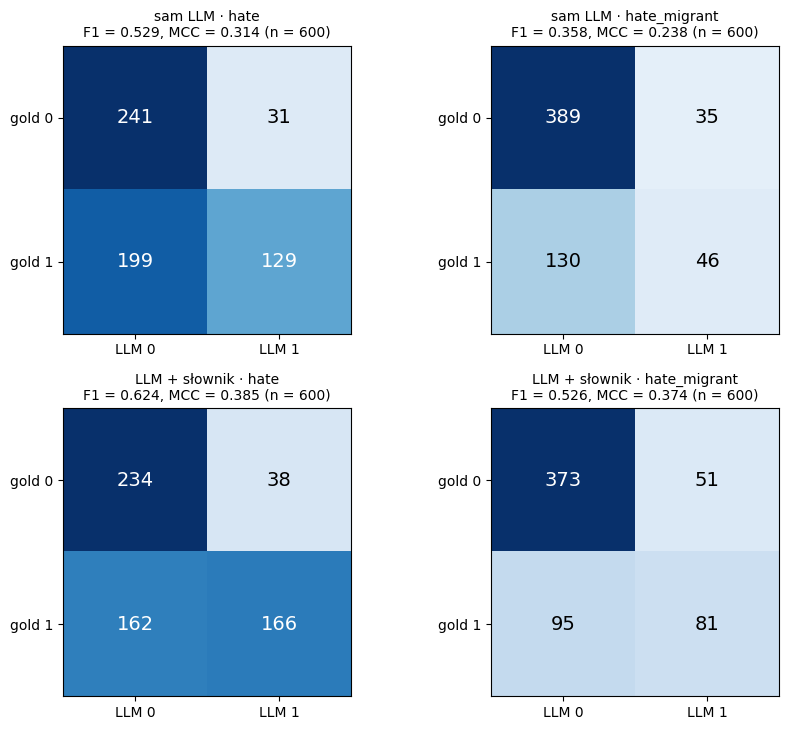

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(9, 7.4))
for row, (variant, (ph, pm)) in zip(axes, VARIANTS.items()):
    for ax, (task, yc, pc) in zip(row, [("hate", "gold_hate", ph), ("hate_migrant", "gold_hate_migrant", pm)]):
        s = scores(ev[yc], ev[pc])
        mat = np.array([[s["tn"], s["fp"]], [s["fn"], s["tp"]]])
        ax.imshow(mat, cmap="Blues", vmin=0, vmax=mat.max())
        for (i, j), v in np.ndenumerate(mat):
            ax.text(j, i, str(v), ha="center", va="center", fontsize=14, color="white" if v > mat.max() / 2 else "black")
        ax.set_xticks([0, 1], ["LLM 0", "LLM 1"]); ax.set_yticks([0, 1], ["gold 0", "gold 1"])
        ax.set_title(f"{variant} · {task}\nF1 = {s['f1']:.3f}, MCC = {s['mcc']:.3f} (n = {s['n']})", fontsize=10)
plt.tight_layout(); plt.show()


## 2a. Etykieta `migrant` (komentarz o migracji)

Gold nie ma osobnej etykiety „o migracji”, ale komentarz z `hate_migrants = 1` z definicji dotyczy migrantów. Sprawdzamy więc,
jaką część takich komentarzy LLM oznaczył jako `migrant` (czułość tematu) oraz jak często LLM oznacza `migrant` w każdej puli
(pule `mig_*` zawierają słowa o migracji, `ambiguous` – nie).

In [6]:
pos = ev[ev["gold_hate_migrant"] == 1]
print(f"gold hate_migrants = 1: {len(pos)} komentarzy, LLM migrant = 1 w {pos['llm_migrant'].mean():.1%}")
display(ev.groupby(["platform", "pool"])["llm_migrant"].agg(["size", "mean"]).rename(columns={"size": "n", "mean": "LLM migrant %"})
        .assign(**{"LLM migrant %": lambda d: (100 * d["LLM migrant %"]).round(1)}))

# hejt trafiony przez LLM: czy dobrze wskazał cel (migranci vs inni)?
both = ev[(ev["gold_hate"] == 1) & (ev["llm_hate"] == 1)]
if len(both):
    s = scores(both["gold_hate_migrant"], both["llm_hate_migrant"])
    print(f"\nKomentarze, które gold i LLM uznały za hejt (n = {len(both)}): zgodność celu (migranci tak/nie) "
          f"accuracy = {s['accuracy']:.3f}, F1(hate_migrant) = {s['f1']:.3f}")

gold hate_migrants = 1: 176 komentarzy, LLM migrant = 1 w 46.0%


n  LLM migrant %
platform pool                          
bluesky  ambiguous    43            4.7
         mig_hostile  80           18.8
         mig_other    77           28.6
wykop    ambiguous    36           11.1
         mig_hostile  84           31.0
         mig_other    80           37.5
youtube  ambiguous    41           29.3
         mig_hostile  76           15.8
         mig_other    83           54.2


Komentarze, które gold i LLM uznały za hejt (n = 166): zgodność celu (migranci tak/nie) accuracy = 0.723, F1(hate_migrant) = 0.779


## 2b. Błędy LLM (do przejrzenia)

In [7]:
txt = "text" if "text" in ev.columns else None
for task, (yc, pc) in TASKS.items():
    e = ev[ev[yc] != ev[pc]].assign(błąd=lambda d: np.where(d[pc] == 1, "FP (LLM: tak)", "FN (LLM: nie)"))
    print(f"\n{task}: {len(e)} błędów")
    display(e.groupby(["platform", "błąd"]).size().unstack(fill_value=0))
    if txt:
        display(e.sort_values(["błąd", "platform"])[["gold_id", "platform", "llm_status", "błąd", txt]].head(25))


hate: 200 błędów


błąd,FN (LLM: nie),FP (LLM: tak)
platform,,
bluesky,47,17
wykop,56,9
youtube,59,12


,gold_id,platform,llm_status,błąd,text
22,gold_v1:P0056,bluesky,Ollama (gold_600_ollama.csv),FN (LLM: nie),"jak oni wszyscy. Stąd pogarda dla ""wykształciuchów"" i gloryfikacja głupoty, lenistwa, postaw roszczeniowych. Tym kupili i nadal posiadają ponad 1/3 Polaków"
23,gold_v1:P0059,bluesky,Ollama (gold_600_ollama.csv),FN (LLM: nie),"Tak, nie można im dać się rozkręcić. To cienkie chujki są."
26,gold_v1:P0062,bluesky,Ollama (gold_600_ollama.csv),FN (LLM: nie),Brak komentarza. Nawet to nie zwierzęta.
38,gold_v1:P0085,bluesky,Ollama (gold_600_ollama.csv),FN (LLM: nie),Sugerował aby państwo pomagało im sprzedawać towary gdyż nie mają możliwości dostać dobrej ceny za to co wyprodukowali. Roszczeniowi jak zwykle.
40,gold_v1:P0088,bluesky,Ollama (gold_600_ollama.csv),FN (LLM: nie),Używając wobec tych osobników nazw różnych zwierząt co bardzo nas kusi... W sumie jest niesprawiedliwe.\nEwentualnie pozostają niektóre owady a najlepszą nazwą na nich byłyby n...
73,gold_v1:P0175,bluesky,Ollama (gold_600_ollama.csv),FN (LLM: nie),"Tak, to ciekawe, bo w tak lubiany przez prawaków imperializm też był w sumie niezły. (OK, musiał łyknąć Afganistan, ale wciąż)"
90,gold_v1:P0222,bluesky,Ollama (gold_600_ollama.csv),FN (LLM: nie),Co chcesz chcą przypodobać sie faszystom by byli dla nich łaskawie jak będą rzadzic
92,gold_v1:P0228,bluesky,Ollama (gold_600_ollama.csv),FN (LLM: nie),To się dzialo I będzie dziać.\nZawsze można odpowiedzieć jak Erdogan i stracić to paskudztwo.\nOlać protesty i mieć spokój na jakiś czas. Ruscy nie latają już nad Turcja bez po...
110,gold_v1:P0265,bluesky,Ollama (gold_600_ollama.csv),FN (LLM: nie),"To nie są tacy sami faszyści. Jeden robi to z głupoty, drugi z wyrachowania dba o swój osobisty interes. Tyle, że na ulicy efekt jest dokładnie taki sam…"
112,gold_v1:P0270,bluesky,Ollama (gold_600_ollama.csv),FN (LLM: nie),"Nikt o tych ludziach nie myślał. Słynne polskie ""jakoś to będzie.\nWykorzystał to kler , konus i reszta hołoty i to tego efekty.\nJak często piszę z prowincja trzeba umieć rozm..."



hate_migrant: 146 błędów


błąd,FN (LLM: nie),FP (LLM: tak)
platform,,
bluesky,10,17
wykop,41,16
youtube,44,18


,gold_id,platform,llm_status,błąd,text
146,gold_v1:P0333,bluesky,Ollama (gold_600_ollama.csv),FN (LLM: nie),"🤣😁🤣\nAle czy my musimy być z tego znani.\nA jeszcze dopowiem jedno, że arabowie murzyni z Centralnej Afryki mają dar do nauki języków, polski łykają w ciągu miesiąca w podstawo..."
159,gold_v1:P0366,bluesky,Ollama (gold_600_ollama.csv),FN (LLM: nie),Gorzej jak UPA bez P 🙃
170,gold_v1:P0390,bluesky,Ollama (gold_600_ollama.csv),FN (LLM: nie),W jakich dokładnie krajach napływ islamistów i hamasowców doprowadził do “modelowego wzrostu”?\nJeśli chodzi o Polskę to polecam\nmigracje.gov.pl -> Statystyki na mapie świata\...
311,gold_v2:P0042,bluesky,Ollama (gold_600_ollama.csv),FN (LLM: nie),Trzeba nagrywać jak te kurwy ukraińskie prowokują.
312,gold_v2:P0043,bluesky,Ollama (gold_600_ollama.csv),FN (LLM: nie),"Większość krajów, otwiera oczy i widzi, że nie tędy droga.\nNie ma i nie będzie zgody na imigrację bez kontroli.\nNie potrzeba nam hord ludzi, tylko tych, którzy są w stanie na..."
366,gold_v2:P0097,bluesky,Ollama (gold_600_ollama.csv),FN (LLM: nie),a ukraince w pl nie pasuja
520,gold_v2:P0251,bluesky,Ollama (gold_600_ollama.csv),FN (LLM: nie),Za co? Większość Polaków chce deportacji Ukrainców.
526,gold_v2:P0257,bluesky,Ollama (gold_600_ollama.csv),FN (LLM: nie),"On nie otrzymał, ale znając jego poglądy rasowe ucieszy się zapewne, że to jego murzyn dostał nagrodę."
559,gold_v2:P0290,bluesky,Ollama (gold_600_ollama.csv),FN (LLM: nie),"Więc mówimy o tym samym - imigracja tak, ale kontrolowana na wzór Australii - oni nielegalnych imigrantów umieszczają poza swoim terytorium w obozach o zaostrzonym rygorze i ni..."
572,gold_v2:P0303,bluesky,Ollama (gold_600_ollama.csv),FN (LLM: nie),"Lepszy nakaz pracy, mogą rowy melioracyjne czyścić - przynajmniej nie będą darmozjadami."


## 3. Zapis

In [8]:
keep = ["gold_id", "round", "item_id", "llm_item_id", "platform", "event_folder", "comment_id", "pool", "gold_hate",
        "gold_hate_migrant", "llm_hate_raw", "llm_hate_migrant_raw", "hate_auto", "hate_migrants_auto", "llm_hate",
        "llm_hate_migrant", "llm_migrant", "w_filtrze", "llm_status", "llm_covered"]
g[keep].to_csv(OUT / "gold_llm_labels.csv", index=False, encoding="utf-8-sig")     # bez treści komentarzy
llm_metrics.to_csv(OUT / "llm_metrics.csv", index=False, encoding="utf-8-sig")
summary = {f"{v} · {t}": llm_metrics[(llm_metrics["etykieta"] == t) & (llm_metrics["wariant"] == v) & (llm_metrics["zakres"] == "ogółem")]
           .iloc[0][["n", "f1", "f1_ci95", "mcc"]].to_dict() for v in VARIANTS for t in ["hate", "hate_migrant"]}
(OUT / "llm_summary.json").write_text(json.dumps({"llm_file": LLM_FILE, "n_gold": len(g), **summary},
                                                 ensure_ascii=False, indent=2, default=str), encoding="utf-8")
for k, s in summary.items():
    print(f"LLM {k}: F1 = {s['f1']:.3f} {s['f1_ci95']}, MCC = {s['mcc']:.3f} (n = {s['n']})")
print("Dalej: 10_hate_models_vs_llm.ipynb – LLM vs HerBERT / Polbert / RoBERTa dla etykiety hate.")


LLM sam LLM · hate: F1 = 0.529 [0.478, 0.581], MCC = 0.314 (n = 600)
LLM sam LLM · hate_migrant: F1 = 0.358 [0.284, 0.431], MCC = 0.238 (n = 600)
LLM LLM + słownik · hate: F1 = 0.624 [0.579, 0.67], MCC = 0.385 (n = 600)
LLM LLM + słownik · hate_migrant: F1 = 0.526 [0.458, 0.589], MCC = 0.374 (n = 600)
Dalej: 10_hate_models_vs_llm.ipynb – LLM vs HerBERT / Polbert / RoBERTa dla etykiety hate.
